## **Inflation pre-processing**

This jupyter notebook is used to pre-process data on inflation.



In [3]:
# Import of necessary packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as st

In [6]:
# Import first part of inflation and rename, add columns
infl1 = pd.read_excel("/Users/jachymsvejda/Documents/GitHub/FIRE_Rule_from_a_Perspective_of_a_Czech_Retail_Investor/data/inflation/INFL_95_17.xlsx", sheet_name="DATA_RAW")
infl1["Classification"] = "COICOP"
infl1.rename(columns={"Classification COICOP" : "Year"}, inplace=True)

In [7]:
# Import second part of inflation and rename, add columns
infl2 = pd.read_excel("/Users/jachymsvejda/Documents/GitHub/FIRE_Rule_from_a_Perspective_of_a_Czech_Retail_Investor/data/inflation/INFL_18_24.xlsx", sheet_name="DATA_RAW")
infl2["Classification"] = "ECOICOP"
infl2.rename(columns={"Classification ECOICOP" : "Year"}, inplace=True)

In [8]:
# Union inflation data and reset index
infl = pd.concat([infl1, infl2]).reset_index()
infl.drop("index",axis=1, inplace=True)

In [9]:
# Transfer data such that Total for 1995 is 100
div = infl[infl['Year'] == 1995]['Total'][0]
infl["Total"] = np.round((infl["Total"] / div) * 100,1)

In [10]:
# Create year-to-year inflation in percentage 
infl["Inflation"] = np.nan
for i in range(1,len(infl)):
    infl.loc[i, "Inflation"] = np.round((infl.loc[i, "Total"] - infl.loc[i-1, "Total"]) / infl.loc[i-1, "Total"], 4)

In [12]:
# Define empirical mean and variance
infl_mean, infl_var = np.mean(infl["Inflation"]), np.std(infl["Inflation"])


In [14]:
# Inflation of Housing only
house = pd.read_excel("/Users/jachymsvejda/Documents/GitHub/FIRE_Rule_from_a_Perspective_of_a_Czech_Retail_Investor/data/inflation/Housing_inflation.xlsx")

In [15]:
# Transfer data such that Total for 1995 is 100
div_house = house[house['Year'] == 1996].iloc[0,1]
house["Total"] = np.round((house["Housing (2015=100)"] / div_house) * 100, 1)

In [16]:
# Change ordering such that it is the same as in infl
house = house.sort_values(by="Year").reset_index().drop("index", axis=1)

In [17]:
# Create year-to-year inflation in percentage 
house["Inflation"] = np.nan
for i in range(1,len(house)):
    house.loc[i, "Inflation"] = np.round((house.loc[i, "Total"] - house.loc[i-1, "Total"]) / house.loc[i-1, "Total"], 4)

In [18]:
# Compare inflation of housing only and total inflation
np.mean(house[house["Year"]>1996]["Inflation"]), np.mean(infl[infl["Year"]>1996]["Inflation"])

(np.float64(0.04661071428571429), np.float64(0.03620357142857143))

In [19]:
# Contribution of inflation of housing to total inflation
house_weight = 0.103372152 # Number according to Consumer basket for CPI since January 2024 by Czech Statistical Office
whinfl24 = (house[house["Year"]==2024].iloc[0,3] * house_weight)
print(f"Inflation of housing contributes to total inflation by {round(whinfl24 * 100,4)}%")

Inflation of housing contributes to total inflation by 0.1158%


In [22]:
# Yearly inflation without housing
infl["Infl-Hous"] = infl["Inflation"] - whinfl24

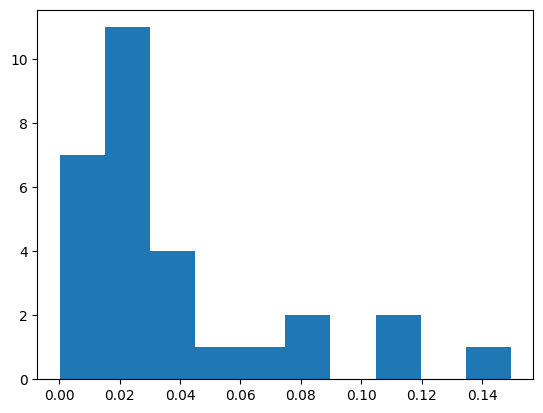

In [28]:
# Histogram of Inflation without Housing
plt.hist(infl["Infl-Hous"])
plt.savefig("/Users/jachymsvejda/Documents/GitHub/FIRE_Rule_from_a_Perspective_of_a_Czech_Retail_Investor/Visualizations/Inflation/Inflation_hist.pdf", format="pdf", bbox_inches="tight")
plt.show()